In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

RANDOM_STATE = 42

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv


In [ ]:
# Customer data
customers = pd.read_csv(
    "olist_customers_dataset.csv"
)

# Order data
orders = pd.read_csv(
    "olist_orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

# Order item data
items = pd.read_csv(
    "olist_order_items_dataset.csv",
    parse_dates=["shipping_limit_date"]
)

# Payment data
payments = pd.read_csv(
    "olist_order_payments_dataset.csv"
)

# Review data
reviews = pd.read_csv(
    "olist_order_reviews_dataset.csv",
    parse_dates=[
        "review_creation_date",
        "review_answer_timestamp"
    ]
)

# Product data
products = pd.read_csv(
    "olist_products_dataset.csv"
)

# Product category translation
category_translation = pd.read_csv(
    "product_category_name_translation.csv"
)

# Seller data
sellers = pd.read_csv(
    "olist_sellers_dataset.csv"
)

# Geolocation data
geolocation = pd.read_csv(
    "olist_geolocation_dataset.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [ ]:
datasets = {
    "customers": customers,
    "orders": orders,
    "items": items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "category_translation": category_translation,
    "sellers": sellers,
    "geolocation": geolocation
}

print("Number of datasets:", len(datasets))

Number of datasets: 9


In [ ]:
summary = pd.DataFrame({
    "rows": {
        name: df.shape[0]
        for name, df in datasets.items()
    },

    "columns": {
        name: df.shape[1]
        for name, df in datasets.items()
    },

    "duplicate_rows": {
        name: df.duplicated().sum()
        for name, df in datasets.items()
    },

    "missing_cells": {
        name: df.isnull().sum().sum()
        for name, df in datasets.items()
    }
})

display(summary)

,rows,columns,duplicate_rows,missing_cells
customers,99441,5,0,0
orders,99441,8,0,4908
items,112650,7,0,0
payments,103886,5,0,0
reviews,99224,7,0,145903
products,32951,9,0,2448
category_translation,71,2,0,0
sellers,3095,4,0,0
geolocation,1000163,5,261831,0


In [ ]:
for name, df in datasets.items():
    print("=" * 80)
    print(name.upper())
    print("=" * 80)

    print(df.columns.tolist())
    print()

CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PAYMENTS
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

REVIEWS
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

CATEGORY_TRANSLATION
['product_category_name', 'product_category_name_english']

SELLERS
['seller_id', 'seller_zip_

In [ ]:
for name, df in datasets.items():
    print("\n")
    print("=" * 80)
    print(name.upper())
    print("=" * 80)

    display(df.head(3))



CUSTOMERS


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP




ORDERS


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04




ITEMS


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87


... (8 outputs left out)



SELLERS


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ




GEOLOCATION


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP


In [ ]:
print(
    "Earliest purchase:",
    orders["order_purchase_timestamp"].min()
)

print(
    "Latest purchase:",
    orders["order_purchase_timestamp"].max()
)

print(
    "Observation period:",
    orders["order_purchase_timestamp"].max()
    - orders["order_purchase_timestamp"].min()
)

Earliest purchase: 2016-09-04 21:15:19
Latest purchase: 2018-10-17 17:30:18
Observation period: 772 days 20:14:59


In [ ]:
order_status = (
    orders["order_status"]
    .value_counts(dropna=False)
    .to_frame("count")
)

order_status["percentage"] = (
    order_status["count"]
    / len(orders)
    * 100
)

display(order_status)

,count,percentage
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


In [ ]:
print("Number of customer_id:",
      customers["customer_id"].nunique())

print("Number of customer_unique_id:",
      customers["customer_unique_id"].nunique())

print("Duplicate customer_id:",
      customers["customer_id"].duplicated().sum())

print("Duplicate customer_unique_id:",
      customers["customer_unique_id"].duplicated().sum())

Number of customer_id: 99441
Number of customer_unique_id: 96096
Duplicate customer_id: 0
Duplicate customer_unique_id: 3345


In [ ]:
orders_per_customer = (
    orders
    .merge(
        customers[
            ["customer_id", "customer_unique_id"]
        ],
        on="customer_id",
        how="left"
    )
    .groupby("customer_unique_id")
    ["order_id"]
    .nunique()
)

print("Customers:", len(orders_per_customer))

print(
    "Customers with more than 1 order:",
    (orders_per_customer > 1).sum()
)

print(
    "Percentage of repeat customers:",
    round(
        (orders_per_customer > 1).mean() * 100,
        2
    ),
    "%"
)

display(orders_per_customer.describe())

Customers: 96096
Customers with more than 1 order: 2997
Percentage of repeat customers: 3.12 %


,order_id
count,"96,096.00"
mean,1.03
std,0.21
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,17.00


In [ ]:
for name, df in datasets.items():

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:

        missing_table = pd.DataFrame({
            "missing_count": missing,
            "missing_percentage":
                (missing / len(df) * 100).round(2)
        })

        print("\n" + "=" * 80)
        print(name.upper())
        print("=" * 80)

        display(
            missing_table.sort_values(
                "missing_percentage",
                ascending=False
            )
        )


ORDERS


,missing_count,missing_percentage
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16



REVIEWS


,missing_count,missing_percentage
review_comment_title,87656,88.34
review_comment_message,58247,58.70



PRODUCTS


,missing_count,missing_percentage
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


BƯỚC 3: Data Cleaning

In [ ]:
order_status = (
    orders["order_status"]
    .value_counts(dropna=False)
    .to_frame("count")
)

order_status["percentage"] = (
    order_status["count"]
    / len(orders)
    * 100
).round(2)

display(order_status)

,count,percentage
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


In [ ]:
delivery_missing_by_status = (
    orders
    .assign(
        missing_delivery=
        orders["order_delivered_customer_date"].isna()
    )
    .groupby("order_status")
    .agg(
        total_orders=("order_id", "count"),
        missing_delivery=("missing_delivery", "sum")
    )
)

delivery_missing_by_status["missing_percentage"] = (
    delivery_missing_by_status["missing_delivery"]
    / delivery_missing_by_status["total_orders"]
    * 100
).round(2)

display(delivery_missing_by_status)

,total_orders,missing_delivery,missing_percentage
order_status,,,
approved,2,2,100.00
canceled,625,619,99.04
created,5,5,100.00
delivered,96478,8,0.01
invoiced,314,314,100.00
processing,301,301,100.00
shipped,1107,1107,100.00
unavailable,609,609,100.00


In [ ]:
orders_clean = orders[
    orders["order_status"] == "delivered"
].copy()

print("Original orders:", len(orders))
print("Delivered orders:", len(orders_clean))
print("Orders removed:", len(orders) - len(orders_clean))

print(
    "Retention rate:",
    round(len(orders_clean) / len(orders) * 100, 2),
    "%"
)

Original orders: 99441
Delivered orders: 96478
Orders removed: 2963
Retention rate: 97.02 %


In [ ]:
orders_clean = orders_clean.merge(
    customers[
        [
            "customer_id",
            "customer_unique_id",
            "customer_city",
            "customer_state"
        ]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Rows after customer merge:", len(orders_clean))

print(
    "Missing customer_unique_id:",
    orders_clean["customer_unique_id"].isna().sum()
)

print(
    "Unique customers:",
    orders_clean["customer_unique_id"].nunique()
)

Rows after customer merge: 96478
Missing customer_unique_id: 0
Unique customers: 93358


In [ ]:
items_order = (
    items
    .groupby("order_id")
    .agg(
        total_item_value=("price", "sum"),
        total_freight_value=("freight_value", "sum"),
        number_of_items=("order_item_id", "count"),
        number_of_products=("product_id", "nunique"),
        number_of_sellers=("seller_id", "nunique")
    )
    .reset_index()
)

print("Original item rows:", len(items))
print("Order-level item rows:", len(items_order))

display(items_order.head())

Original item rows: 112650
Order-level item rows: 98666


,order_id,total_item_value,total_freight_value,number_of_items,number_of_products,number_of_sellers
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,1,1
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,1,1
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,1,1
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,1,1


In [ ]:
payments_order = (
    payments
    .groupby("order_id")
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max"),
        number_of_payment_records=("payment_sequential", "count"),
        number_of_payment_types=("payment_type", "nunique")
    )
    .reset_index()
)

print("Original payment rows:", len(payments))
print("Order-level payment rows:", len(payments_order))

display(payments_order.head())

Original payment rows: 103886
Order-level payment rows: 99440


,order_id,payment_value,payment_installments,number_of_payment_records,number_of_payment_types
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,2,1,1
1,00018f77f2f0320c557190d7a144bdd3,259.83,3,1,1
2,000229ec398224ef6ca0657da4fc703e,216.87,5,1,1
3,00024acbcdf0a6daa1e931b038114c75,25.78,2,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,3,1,1


In [ ]:
reviews_order = (
    reviews
    .groupby("order_id")
    .agg(
        avg_review_score=("review_score", "mean"),
        min_review_score=("review_score", "min"),
        number_of_reviews=("review_id", "count"),
        has_review_comment=(
            "review_comment_message",
            lambda x: x.notna().any()
        )
    )
    .reset_index()
)

print("Order-level review rows:", len(reviews_order))
display(reviews_order.head())

Order-level review rows: 98673


,order_id,avg_review_score,min_review_score,number_of_reviews,has_review_comment
0,00010242fe8c5a6d1ba2dd792cb16214,5.00,5,1,True
1,00018f77f2f0320c557190d7a144bdd3,4.00,4,1,False
2,000229ec398224ef6ca0657da4fc703e,5.00,5,1,True
3,00024acbcdf0a6daa1e931b038114c75,4.00,4,1,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.00,5,1,True


In [ ]:
reviews_order = (
    reviews
    .groupby("order_id")
    .agg(
        avg_review_score=("review_score", "mean"),
        min_review_score=("review_score", "min"),
        number_of_reviews=("review_id", "count"),
        has_review_comment=(
            "review_comment_message",
            lambda x: x.notna().any()
        )
    )
    .reset_index()
)

print("Original review rows:", len(reviews))
print("Order-level review rows:", len(reviews_order))

display(reviews_order.head())

Original review rows: 99224
Order-level review rows: 98673


,order_id,avg_review_score,min_review_score,number_of_reviews,has_review_comment
0,00010242fe8c5a6d1ba2dd792cb16214,5.00,5,1,True
1,00018f77f2f0320c557190d7a144bdd3,4.00,4,1,False
2,000229ec398224ef6ca0657da4fc703e,5.00,5,1,True
3,00024acbcdf0a6daa1e931b038114c75,4.00,4,1,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.00,5,1,True


In [ ]:
review_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

review_distribution["percentage"] = (
    review_distribution["count"]
    / len(reviews)
    * 100
).round(2)

display(review_distribution)

print(
    "Average review score:",
    round(reviews["review_score"].mean(), 2)
)

,count,percentage
review_score,,
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78


Average review score: 4.09


In [ ]:
reviews_order = (
    reviews
    .groupby("order_id")
    .agg(
        avg_review_score=("review_score", "mean"),
        min_review_score=("review_score", "min"),
        number_of_reviews=("review_id", "count"),
        has_review_comment=(
            "review_comment_message",
            lambda x: x.notna().any()
        )
    )
    .reset_index()
)

print("Original review rows:", len(reviews))
print("Order-level review rows:", len(reviews_order))

display(reviews_order.head())

Original review rows: 99224
Order-level review rows: 98673


,order_id,avg_review_score,min_review_score,number_of_reviews,has_review_comment
0,00010242fe8c5a6d1ba2dd792cb16214,5.00,5,1,True
1,00018f77f2f0320c557190d7a144bdd3,4.00,4,1,False
2,000229ec398224ef6ca0657da4fc703e,5.00,5,1,True
3,00024acbcdf0a6daa1e931b038114c75,4.00,4,1,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.00,5,1,True


In [ ]:
products_en = products.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

print("Products:", len(products_en))

print(
    "Missing English category:",
    products_en["product_category_name_english"].isna().sum()
)

display(
    products_en[
        [
            "product_id",
            "product_category_name",
            "product_category_name_english"
        ]
    ].head()
)


Products: 32951
Missing English category: 623


,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


In [ ]:
items_product = items.merge(
    products_en[
        [
            "product_id",
            "product_category_name_english"
        ]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Những sản phẩm không xác định được category
# sẽ được gán nhãn "unknown"
items_product["product_category_name_english"] = (
    items_product["product_category_name_english"]
    .fillna("unknown")
)

# Aggregate về order-level
product_order = (
    items_product
    .groupby("order_id")
    .agg(
        number_of_categories=(
            "product_category_name_english",
            "nunique"
        )
    )
    .reset_index()
)

print("Item-product rows:", len(items_product))
print("Order-level product rows:", len(product_order))

display(product_order.head())

Item-product rows: 112650
Order-level product rows: 98666


,order_id,number_of_categories
0,00010242fe8c5a6d1ba2dd792cb16214,1
1,00018f77f2f0320c557190d7a144bdd3,1
2,000229ec398224ef6ca0657da4fc703e,1
3,00024acbcdf0a6daa1e931b038114c75,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1


In [ ]:
master_orders = (
    orders_clean

    .merge(
        items_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        payments_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        reviews_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        product_order,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

print("Master rows:",
      len(master_orders))

print(
    "Unique orders:",
    master_orders["order_id"].nunique()
)

print(
    "Unique customers:",
    master_orders["customer_unique_id"].nunique()
)

print("\nMissing values:")

display(
    master_orders
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

display(master_orders.head())

Master rows: 96478
Unique orders: 96478
Unique customers: 93358

Missing values:


,0
min_review_score,646
avg_review_score,646
has_review_comment,646
number_of_reviews,646
order_approved_at,14
order_delivered_customer_date,8
order_delivered_carrier_date,2
payment_installments,1
payment_value,1
number_of_payment_records,1


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,total_item_value,total_freight_value,number_of_items,number_of_products,number_of_sellers,payment_value,payment_installments,number_of_payment_records,number_of_payment_types,avg_review_score,min_review_score,number_of_reviews,has_review_comment,number_of_categories
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,29.99,8.72,1,1,1,38.71,1.00,3.00,2.00,4.00,4.00,1.00,True,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,118.70,22.76,1,1,1,141.46,1.00,1.00,1.00,4.00,4.00,1.00,True,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,159.90,19.22,1,1,1,179.12,3.00,1.00,1.00,5.00,5.00,1.00,False,1
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,45.00,27.20,1,1,1,72.20,1.00,1.00,1.00,5.00,5.00,1.00,True,1
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,19.90,8.72,1,1,1,28.62,1.00,1.00,1.00,5.00,5.00,1.00,False,1


Tiếp theo: EDA + RFM

In [ ]:
# Reference date = 1 day after last purchase
reference_date = (
    master_orders["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

rfm = (
    master_orders
    .groupby("customer_unique_id")
    .agg(
        Recency=(
            "order_purchase_timestamp",
            lambda x: (reference_date - x.max()).days
        ),
        Frequency=("order_id", "nunique"),
        Monetary=("payment_value", "sum")
    )
    .reset_index()
)

print("Reference date:", reference_date)
print("RFM customers:", len(rfm))

display(rfm.head())

display(
    rfm[["Recency", "Frequency", "Monetary"]]
    .describe()
)

Reference date: 2018-08-30 15:00:37
RFM customers: 93358


,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19
2,0000f46a3911fa3c0805444483337064,537,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89


,Recency,Frequency,Monetary
count,"93,358.00","93,358.00","93,358.00"
mean,237.94,1.03,165.20
std,152.59,0.21,226.31
min,1.00,1.00,0.00
25%,114.00,1.00,63.05
50%,219.00,1.00,107.78
75%,346.00,1.00,182.56
max,714.00,15.00,"13,664.08"


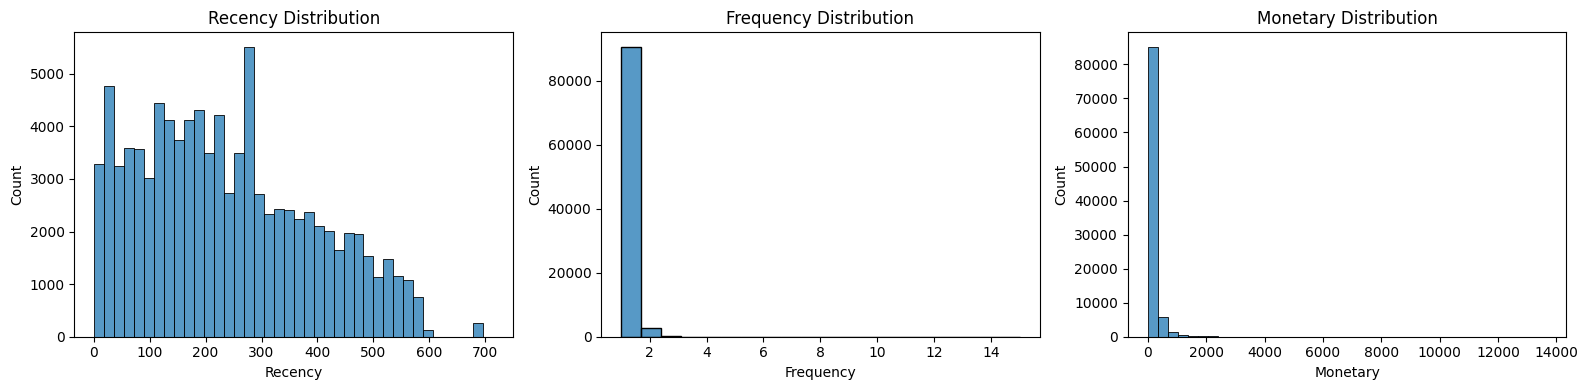

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(
    rfm["Recency"],
    bins=40,
    ax=axes[0]
)
axes[0].set_title("Recency Distribution")

sns.histplot(
    rfm["Frequency"],
    bins=20,
    ax=axes[1]
)
axes[1].set_title("Frequency Distribution")

sns.histplot(
    rfm["Monetary"],
    bins=40,
    ax=axes[2]
)
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()

In [ ]:
print("Skewness")

for col in ["Recency", "Frequency", "Monetary"]:
    print(
        col,
        ":",
        round(rfm[col].skew(), 2)
    )

print("\nFrequency counts:")
display(
    rfm["Frequency"]
    .value_counts()
    .sort_index()
    .head(15)
)

print("\nMonetary percentiles:")
display(
    rfm["Monetary"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
)

Skewness
Recency : 0.45
Frequency : 11.1
Monetary : 9.21

Frequency counts:


,count
Frequency,
1,90557
2,2573
3,181
4,28
5,9
6,5
7,3
9,1
15,1



Monetary percentiles:


,Monetary
0.50,107.78
0.75,182.56
0.90,318.07
0.95,469.62
0.99,"1,097.06"
1.00,"13,664.08"


In [ ]:
#Transform RFM cho K-Means
from sklearn.preprocessing import StandardScaler

rfm_model = rfm.copy()

# Log transform để giảm skewness
rfm_model["Recency_log"] = np.log1p(rfm_model["Recency"])
rfm_model["Frequency_log"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary_log"] = np.log1p(rfm_model["Monetary"])

# Kiểm tra skewness sau transform
print("Skewness after log transformation:")

for col in ["Recency_log", "Frequency_log", "Monetary_log"]:
    print(col, ":", round(rfm_model[col].skew(), 2))

# Standardize
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_model[
        ["Recency_log", "Frequency_log", "Monetary_log"]
    ]
)

print("\nScaled RFM shape:", rfm_scaled.shape)

Skewness after log transformation:
Recency_log : -1.22
Frequency_log : 6.52
Monetary_log : 0.53

Scaled RFM shape: (93358, 3)


In [ ]:
#Tìm số cluster K phù hợp
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []

K_range = range(2, 9)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(
            rfm_scaled,
            labels,
            sample_size=20000,
            random_state=RANDOM_STATE
        )
    )

results_k = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertia,
    "Silhouette": silhouette_scores
})

display(results_k)

,K,Inertia,Silhouette
0,2,"190,214.60",0.71
1,3,"129,158.67",0.42
2,4,"82,907.90",0.40
3,5,"68,332.57",0.36
4,6,"58,433.33",0.35
5,7,"51,228.92",0.35
6,8,"45,849.40",0.35


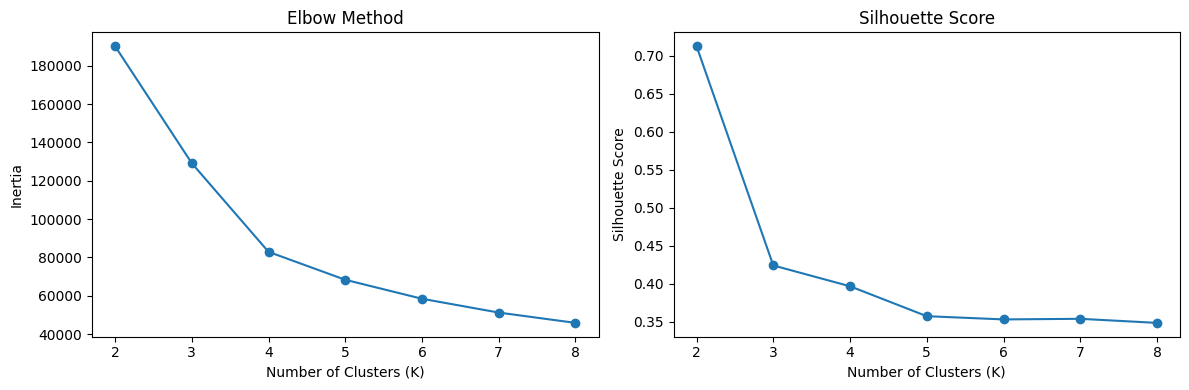

In [ ]:
#Vẽ Elbow + Silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    results_k["K"],
    results_k["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    results_k["K"],
    results_k["Silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [ ]:
#Chạy K-Means chính thức
final_kmeans = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=10
)

rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

print("Cluster sizes:")
display(
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster percentages:")
display(
    (
        rfm["Cluster"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)

Cluster sizes:


,count
Cluster,
0,32165
1,42220
2,2801
3,16172



Cluster percentages:


,proportion
Cluster,
0,34.45
1,45.22
2,3.00
3,17.32


In [ ]:
#Profile từng cluster
cluster_profile = (
    rfm
    .groupby("Cluster")
    .agg(
        Customers=("customer_unique_id", "count"),
        Avg_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median")
    )
    .round(2)
)

cluster_profile["Percentage"] = (
    cluster_profile["Customers"]
    / len(rfm)
    * 100
).round(2)

display(cluster_profile)

,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Percentage
Cluster,,,,,,,
0,32165,272.52,255.00,1.00,295.93,199.40,34.45
1,42220,287.72,270.00,1.00,68.21,65.88,45.22
2,2801,220.29,199.00,2.11,308.59,225.55,3.00
3,16172,42.26,38.00,1.00,133.54,103.68,17.32


In [ ]:
#Gắn tên cluster
cluster_names = {
    0: "High-Value Inactive",
    1: "Low-Value Inactive",
    2: "Loyal / Repeat Customers",
    3: "Recent Customers"
}

rfm["Segment"] = rfm["Cluster"].map(cluster_names)

display(
    rfm[
        ["customer_unique_id",
         "Recency",
         "Frequency",
         "Monetary",
         "Cluster",
         "Segment"]
    ].head()
)

display(
    rfm["Segment"]
    .value_counts()
)


,customer_unique_id,Recency,Frequency,Monetary,Cluster,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,0,High-Value Inactive
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,1,Low-Value Inactive
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,Low-Value Inactive
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,1,Low-Value Inactive
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,0,High-Value Inactive


,count
Segment,
Low-Value Inactive,42220
High-Value Inactive,32165
Recent Customers,16172
Loyal / Repeat Customers,2801


Churn Prediction

In [ ]:
# Chỉ lấy ngày mua
temp = master_orders[
    ["customer_unique_id",
     "order_id",
     "order_purchase_timestamp"]
].copy()

test_settings = []

cutoff_dates = [
    "2018-03-01",
    "2018-04-01",
    "2018-05-01",
    "2018-06-01"
]

windows = [60, 90, 120]

for cutoff_str in cutoff_dates:

    cutoff = pd.Timestamp(cutoff_str)

    # Customers observed before cutoff
    historical_customers = set(
        temp.loc[
            temp["order_purchase_timestamp"] < cutoff,
            "customer_unique_id"
        ]
    )

    for window in windows:

        future_end = cutoff + pd.Timedelta(days=window)

        returned_customers = set(
            temp.loc[
                (temp["order_purchase_timestamp"] >= cutoff) &
                (temp["order_purchase_timestamp"] < future_end),
                "customer_unique_id"
            ]
        )

        n_hist = len(historical_customers)

        n_returned = len(
            historical_customers.intersection(
                returned_customers
            )
        )

        return_rate = (
            n_returned / n_hist * 100
            if n_hist > 0 else 0
        )

        test_settings.append({
            "cutoff_date": cutoff.date(),
            "future_window_days": window,
            "historical_customers": n_hist,
            "returned_customers": n_returned,
            "return_rate_pct": round(return_rate, 2),
            "non_return_rate_pct": round(
                100 - return_rate, 2
            )
        })

churn_window_test = pd.DataFrame(test_settings)

display(churn_window_test)

,cutoff_date,future_window_days,historical_customers,returned_customers,return_rate_pct,non_return_rate_pct
0,2018-03-01,60,55525,264,0.48,99.52
1,2018-03-01,90,55525,386,0.70,99.30
2,2018-03-01,120,55525,488,0.88,99.12
3,2018-04-01,60,62299,301,0.48,99.52
4,2018-04-01,90,62299,421,0.68,99.32
5,2018-04-01,120,62299,506,0.81,99.19
6,2018-05-01,60,68881,328,0.48,99.52
7,2018-05-01,90,68881,430,0.62,99.38
8,2018-05-01,120,68881,538,0.78,99.22
9,2018-06-01,60,75387,304,0.40,99.60


In [ ]:
#Transform RFM cho K-Means
from sklearn.preprocessing import StandardScaler

rfm_model = rfm.copy()

# Log transform để giảm skewness
rfm_model["Recency_log"] = np.log1p(rfm_model["Recency"])
rfm_model["Frequency_log"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary_log"] = np.log1p(rfm_model["Monetary"])

# Kiểm tra skewness sau transform
print("Skewness after log transformation:")

for col in ["Recency_log", "Frequency_log", "Monetary_log"]:
    print(col, ":", round(rfm_model[col].skew(), 2))

# Standardize
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_model[
        ["Recency_log", "Frequency_log", "Monetary_log"]
    ]
)

print("\nScaled RFM shape:", rfm_scaled.shape)

Skewness after log transformation:
Recency_log : -1.22
Frequency_log : 6.52
Monetary_log : 0.53

Scaled RFM shape: (93358, 3)


In [ ]:
#Tìm số cluster K phù hợp
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []

K_range = range(2, 9)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(
            rfm_scaled,
            labels,
            sample_size=20000,
            random_state=RANDOM_STATE
        )
    )

results_k = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertia,
    "Silhouette": silhouette_scores
})

display(results_k)

,K,Inertia,Silhouette
0,2,"190,214.60",0.71
1,3,"129,158.67",0.42
2,4,"82,907.90",0.40
3,5,"68,332.57",0.36
4,6,"58,433.33",0.35
5,7,"51,228.92",0.35
6,8,"45,849.40",0.35


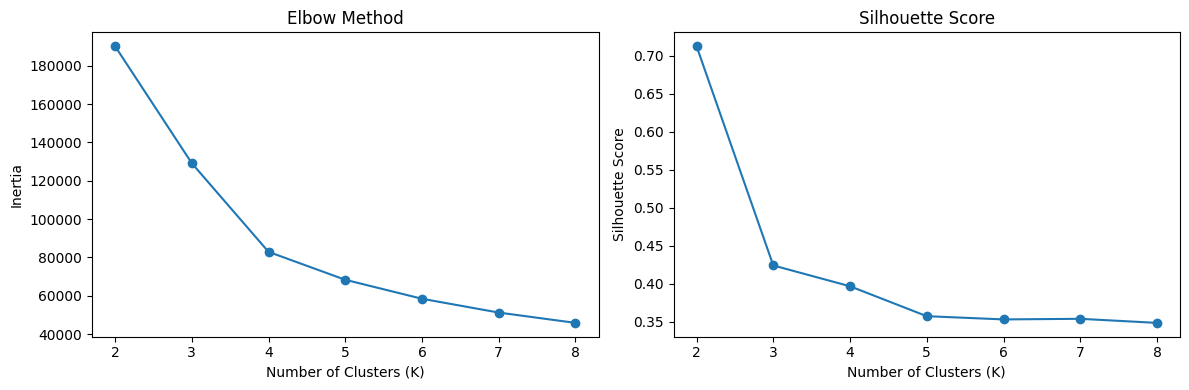

In [ ]:
#Vẽ Elbow + Silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    results_k["K"],
    results_k["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    results_k["K"],
    results_k["Silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [ ]:
# Chỉ lấy ngày mua
temp = master_orders[
    ["customer_unique_id",
     "order_id",
     "order_purchase_timestamp"]
].copy()

test_settings = []

cutoff_dates = [
    "2018-03-01",
    "2018-04-01",
    "2018-05-01",
    "2018-06-01"
]

windows = [60, 90, 120]

for cutoff_str in cutoff_dates:

    cutoff = pd.Timestamp(cutoff_str)

    # Customers observed before cutoff
    historical_customers = set(
        temp.loc[
            temp["order_purchase_timestamp"] < cutoff,
            "customer_unique_id"
        ]
    )

    for window in windows:

        future_end = cutoff + pd.Timedelta(days=window)

        returned_customers = set(
            temp.loc[
                (temp["order_purchase_timestamp"] >= cutoff) &
                (temp["order_purchase_timestamp"] < future_end),
                "customer_unique_id"
            ]
        )

        n_hist = len(historical_customers)

        n_returned = len(
            historical_customers.intersection(
                returned_customers
            )
        )

        return_rate = (
            n_returned / n_hist * 100
            if n_hist > 0 else 0
        )

        test_settings.append({
            "cutoff_date": cutoff.date(),
            "future_window_days": window,
            "historical_customers": n_hist,
            "returned_customers": n_returned,
            "return_rate_pct": round(return_rate, 2),
            "non_return_rate_pct": round(
                100 - return_rate, 2
            )
        })

churn_window_test = pd.DataFrame(test_settings)

display(churn_window_test)

,cutoff_date,future_window_days,historical_customers,returned_customers,return_rate_pct,non_return_rate_pct
0,2018-03-01,60,55525,264,0.48,99.52
1,2018-03-01,90,55525,386,0.70,99.30
2,2018-03-01,120,55525,488,0.88,99.12
3,2018-04-01,60,62299,301,0.48,99.52
4,2018-04-01,90,62299,421,0.68,99.32
5,2018-04-01,120,62299,506,0.81,99.19
6,2018-05-01,60,68881,328,0.48,99.52
7,2018-05-01,90,68881,430,0.62,99.38
8,2018-05-01,120,68881,538,0.78,99.22
9,2018-06-01,60,75387,304,0.40,99.60


In [ ]:
temp = master_orders[
    [
        "customer_unique_id",
        "order_id",
        "order_purchase_timestamp"
    ]
].copy()

results = []

cutoff_dates = [
    "2018-03-01",
    "2018-04-01",
    "2018-05-01",
    "2018-06-01"
]

windows = [60, 90, 120]

for cutoff_str in cutoff_dates:

    cutoff = pd.Timestamp(cutoff_str)

    history = temp[
        temp["order_purchase_timestamp"] < cutoff
    ]

    historical_frequency = (
        history
        .groupby("customer_unique_id")["order_id"]
        .nunique()
    )

    # Chỉ khách đã mua >= 2 lần trước cutoff
    repeat_customers = set(
        historical_frequency[
            historical_frequency >= 2
        ].index
    )

    for window in windows:

        future_end = (
            cutoff
            + pd.Timedelta(days=window)
        )

        future_customers = set(
            temp.loc[
                (
                    temp["order_purchase_timestamp"]
                    >= cutoff
                )
                &
                (
                    temp["order_purchase_timestamp"]
                    < future_end
                ),
                "customer_unique_id"
            ]
        )

        returned = len(
            repeat_customers.intersection(
                future_customers
            )
        )

        total = len(repeat_customers)

        results.append({
            "cutoff_date": cutoff.date(),
            "future_window_days": window,
            "repeat_customers_before_cutoff": total,
            "returned_customers": returned,
            "return_rate_pct":
                round(returned / total * 100, 2)
                if total else 0,
            "churn_rate_pct":
                round((1 - returned / total) * 100, 2)
                if total else 0
        })

repeat_churn_test = pd.DataFrame(results)

display(repeat_churn_test)

,cutoff_date,future_window_days,repeat_customers_before_cutoff,returned_customers,return_rate_pct,churn_rate_pct
0,2018-03-01,60,1623,36,2.22,97.78
1,2018-03-01,90,1623,47,2.90,97.10
2,2018-03-01,120,1623,56,3.45,96.55
3,2018-04-01,60,1829,37,2.02,97.98
4,2018-04-01,90,1829,48,2.62,97.38
5,2018-04-01,120,1829,53,2.90,97.10
6,2018-05-01,60,2017,37,1.83,98.17
7,2018-05-01,90,2017,44,2.18,97.82
8,2018-05-01,120,2017,55,2.73,97.27
9,2018-06-01,60,2230,30,1.35,98.65


In [ ]:
#Tạo cohort để dự đoán khách không mua lại
# Lấy ngày cuối cùng của dataset
data_end = master_orders["order_purchase_timestamp"].max()

FOLLOW_UP_DAYS = 180
cohort_end = data_end - pd.Timedelta(days=FOLLOW_UP_DAYS)

print("Dataset end:", data_end)
print("Cohort cutoff:", cohort_end)

# Sắp xếp giao dịch theo customer và thời gian
customer_orders = master_orders.sort_values(
    ["customer_unique_id", "order_purchase_timestamp"]
).copy()

# Thứ tự order của từng customer
customer_orders["order_number"] = (
    customer_orders
    .groupby("customer_unique_id")
    .cumcount() + 1
)

# First order
first_orders = (
    customer_orders[
        customer_orders["order_number"] == 1
    ]
    .copy()
)

# Chỉ giữ customer có đủ 180 ngày follow-up
cohort = first_orders[
    first_orders["order_purchase_timestamp"] <= cohort_end
].copy()

print("Eligible customers:", len(cohort))

Dataset end: 2018-08-29 15:00:37
Cohort cutoff: 2018-03-02 15:00:37
Eligible customers: 55907


In [ ]:
second_orders = (
    customer_orders[
        customer_orders["order_number"] == 2
    ][
        [
            "customer_unique_id",
            "order_purchase_timestamp"
        ]
    ]
    .rename(
        columns={
            "order_purchase_timestamp":
            "second_purchase_date"
        }
    )
)

cohort = cohort.merge(
    second_orders,
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

cohort["days_to_second_purchase"] = (
    cohort["second_purchase_date"]
    - cohort["order_purchase_timestamp"]
).dt.days

cohort["Repeat_180d"] = (
    cohort["days_to_second_purchase"]
    .between(1, FOLLOW_UP_DAYS)
).astype(int)

cohort["Churn_Risk"] = 1 - cohort["Repeat_180d"]

print("Eligible customers:", len(cohort))

print("\nTarget counts:")
print(cohort["Churn_Risk"].value_counts())

print("\nTarget percentages:")
print(
    (
        cohort["Churn_Risk"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)

print(
    "\nRepeat rate within 180 days:",
    round(cohort["Repeat_180d"].mean() * 100, 2),
    "%"
)

Eligible customers: 55907

Target counts:
Churn_Risk
1    54849
0     1058
Name: count, dtype: int64

Target percentages:
Churn_Risk
1   98.11
0    1.89
Name: proportion, dtype: float64

Repeat rate within 180 days: 1.89 %


In [ ]:
# Distribution of customer recency
recency_percentiles = rfm["Recency"].quantile(
    [0.25, 0.50, 0.60, 0.70, 0.75, 0.80, 0.90]
)

print("Recency percentiles:")
display(recency_percentiles)

# Test potential inactivity thresholds
thresholds = [90, 120, 150, 180, 210, 240]

risk_test = []

for days in thresholds:

    n_risk = (rfm["Recency"] > days).sum()
    n_active = (rfm["Recency"] <= days).sum()

    risk_test.append({
        "inactivity_threshold_days": days,
        "high_risk_customers": n_risk,
        "active_customers": n_active,
        "high_risk_pct":
            round(n_risk / len(rfm) * 100, 2),
        "active_pct":
            round(n_active / len(rfm) * 100, 2)
    })

risk_threshold_test = pd.DataFrame(risk_test)

display(risk_threshold_test)

Recency percentiles:


,Recency
0.25,114.00
0.50,219.00
0.60,268.00
0.70,312.00
0.75,346.00
0.80,382.00
0.90,466.00


,inactivity_threshold_days,high_risk_customers,active_customers,high_risk_pct,active_pct
0,90,74899,18459,80.23,19.77
1,120,68438,24920,73.31,26.69
2,150,61761,31597,66.16,33.84
3,180,55252,38106,59.18,40.82
4,210,48461,44897,51.91,48.09
5,240,41766,51592,44.74,55.26


In [ ]:
#Tạo target Churn_Risk
customer_model = rfm.copy()

CHURN_THRESHOLD = 180

customer_model["Churn_Risk"] = (
    customer_model["Recency"] > CHURN_THRESHOLD
).astype(int)

print("Target distribution:")

display(
    pd.DataFrame({
        "Count":
            customer_model["Churn_Risk"]
            .value_counts()
            .sort_index(),

        "Percentage":
            (
                customer_model["Churn_Risk"]
                .value_counts(normalize=True)
                .sort_index()
                * 100
            ).round(2)
    })
)

Target distribution:


,Count,Percentage
Churn_Risk,,
0,38106,40.82
1,55252,59.18


In [ ]:
#Tạo behavioral features ở customer level
customer_behavior = (
    master_orders
    .groupby("customer_unique_id")
    .agg(
        Frequency=("order_id", "nunique"),

        Monetary=("payment_value", "sum"),

        Avg_Order_Value=("payment_value", "mean"),

        Avg_Item_Value=("total_item_value", "mean"),

        Avg_Freight=("total_freight_value", "mean"),

        Avg_Items_Per_Order=("number_of_items", "mean"),

        Avg_Products_Per_Order=("number_of_products", "mean"),

        Avg_Category_Diversity=("number_of_categories", "mean"),

        Avg_Review_Score=("avg_review_score", "mean"),

        Avg_Installments=("payment_installments", "mean")
    )
    .reset_index()
)

customer_model = (
    customer_model[
        [
            "customer_unique_id",
            "Recency",
            "Churn_Risk"
        ]
    ]
    .merge(
        customer_behavior,
        on="customer_unique_id",
        how="left",
        validate="one_to_one"
    )
)

print("Model dataset shape:", customer_model.shape)

display(customer_model.head())

Model dataset shape: (93358, 13)


,customer_unique_id,Recency,Churn_Risk,Frequency,Monetary,Avg_Order_Value,Avg_Item_Value,Avg_Freight,Avg_Items_Per_Order,Avg_Products_Per_Order,Avg_Category_Diversity,Avg_Review_Score,Avg_Installments
0,0000366f3b9a7992bf8c76cfdf3221e2,112,0,1,141.90,141.90,129.90,12.00,1.00,1.00,1.00,5.00,8.00
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,0,1,27.19,27.19,18.90,8.29,1.00,1.00,1.00,4.00,1.00
2,0000f46a3911fa3c0805444483337064,537,1,1,86.22,86.22,69.00,17.22,1.00,1.00,1.00,3.00,8.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,1,43.62,43.62,25.99,17.63,1.00,1.00,1.00,4.00,4.00
4,0004aac84e0df4da2b147fca70cf8255,288,1,1,196.89,196.89,180.00,16.89,1.00,1.00,1.00,5.00,6.00


In [ ]:
features = [
    "Frequency",
    "Monetary",
    "Avg_Order_Value",
    "Avg_Item_Value",
    "Avg_Freight",
    "Avg_Items_Per_Order",
    "Avg_Products_Per_Order",
    "Avg_Category_Diversity",
    "Avg_Review_Score",
    "Avg_Installments"
]

print("Missing values:")
display(
    customer_model[features]
    .isna()
    .sum()
)

print("\nCorrelation:")
display(
    customer_model[features]
    .corr()
    .round(2)
)

Missing values:


,0
Frequency,0
Monetary,0
Avg_Order_Value,1
Avg_Item_Value,0
Avg_Freight,0
Avg_Items_Per_Order,0
Avg_Products_Per_Order,0
Avg_Category_Diversity,0
Avg_Review_Score,603
Avg_Installments,1



Correlation:


,Frequency,Monetary,Avg_Order_Value,Avg_Item_Value,Avg_Freight,Avg_Items_Per_Order,Avg_Products_Per_Order,Avg_Category_Diversity,Avg_Review_Score,Avg_Installments
Frequency,1.00,0.12,-0.01,-0.01,0.00,0.03,0.03,0.02,0.01,0.02
Monetary,0.12,1.00,0.98,0.98,0.49,0.19,0.08,0.04,-0.04,0.32
Avg_Order_Value,-0.01,0.98,1.00,1.00,0.49,0.19,0.08,0.04,-0.04,0.32
Avg_Item_Value,-0.01,0.98,1.00,1.00,0.41,0.15,0.06,0.03,-0.04,0.32
Avg_Freight,0.00,0.49,0.49,0.41,1.00,0.43,0.19,0.10,-0.09,0.20
Avg_Items_Per_Order,0.03,0.19,0.19,0.15,0.43,1.00,0.47,0.21,-0.13,0.07
Avg_Products_Per_Order,0.03,0.08,0.08,0.06,0.19,0.47,1.00,0.45,-0.11,0.07
Avg_Category_Diversity,0.02,0.04,0.04,0.03,0.10,0.21,0.45,1.00,-0.08,0.05
Avg_Review_Score,0.01,-0.04,-0.04,-0.04,-0.09,-0.13,-0.11,-0.08,1.00,-0.03
Avg_Installments,0.02,0.32,0.32,0.32,0.20,0.07,0.07,0.05,-0.03,1.00


In [ ]:
corr = customer_model[features].corr()

high_corr_pairs = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        value = corr.iloc[i, j]

        if abs(value) >= 0.80:
            high_corr_pairs.append({
                "Feature_1": corr.columns[i],
                "Feature_2": corr.columns[j],
                "Correlation": round(value, 3)
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

display(high_corr_df)

,Feature_1,Feature_2,Correlation
0,Monetary,Avg_Order_Value,0.98
1,Monetary,Avg_Item_Value,0.98
2,Avg_Order_Value,Avg_Item_Value,1.00


In [ ]:
#Train/Test Split + Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

final_features = [
    "Frequency",
    "Monetary",
    "Avg_Freight",
    "Avg_Items_Per_Order",
    "Avg_Products_Per_Order",
    "Avg_Category_Diversity",
    "Avg_Review_Score",
    "Avg_Installments"
]

X = customer_model[final_features].copy()
y = customer_model["Churn_Risk"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTrain target distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest target distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training samples: 74686
Test samples: 18672

Train target distribution:
Churn_Risk
1   59.18
0   40.82
Name: proportion, dtype: float64

Test target distribution:
Churn_Risk
1   59.18
0   40.82
Name: proportion, dtype: float64


In [ ]:
#Logistic Regression
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

log_pred = logistic_model.predict(X_test)
log_prob = logistic_model.predict_proba(X_test)[:, 1]

log_results = {
    "Accuracy": accuracy_score(y_test, log_pred),
    "Precision": precision_score(y_test, log_pred),
    "Recall": recall_score(y_test, log_pred),
    "F1": f1_score(y_test, log_pred),
    "ROC_AUC": roc_auc_score(y_test, log_prob)
}

display(
    pd.DataFrame(
        [log_results],
        index=["Logistic Regression"]
    ).round(4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, log_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        log_pred,
        digits=4
    )
)

,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.59,0.59,0.99,0.74,0.54



Confusion Matrix:
[[  204  7417]
 [  158 10893]]

Classification Report:
              precision    recall  f1-score   support

           0     0.5635    0.0268    0.0511      7621
           1     0.5949    0.9857    0.7420     11051

    accuracy                         0.5943     18672
   macro avg     0.5792    0.5062    0.3966     18672
weighted avg     0.5821    0.5943    0.4600     18672



In [ ]:
#XGBoost
from xgboost import XGBClassifier

# Median imputation
imputer_xgb = SimpleImputer(strategy="median")

X_train_xgb = imputer_xgb.fit_transform(X_train)
X_test_xgb = imputer_xgb.transform(X_test)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="auc",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(
    X_train_xgb,
    y_train
)

xgb_pred = xgb_model.predict(X_test_xgb)
xgb_prob = xgb_model.predict_proba(X_test_xgb)[:, 1]

xgb_results = {
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1": f1_score(y_test, xgb_pred),
    "ROC_AUC": roc_auc_score(y_test, xgb_prob)
}

display(
    pd.DataFrame(
        [log_results, xgb_results],
        index=[
            "Logistic Regression",
            "XGBoost"
        ]
    ).round(4)
)

print("\nXGBoost confusion matrix:")
print(confusion_matrix(y_test, xgb_pred))

print("\nXGBoost classification report:")
print(
    classification_report(
        y_test,
        xgb_pred,
        digits=4
    )
)

,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.59,0.59,0.99,0.74,0.54
XGBoost,0.78,0.77,0.89,0.82,0.86



XGBoost confusion matrix:
[[4690 2931]
 [1252 9799]]

XGBoost classification report:
              precision    recall  f1-score   support

           0     0.7893    0.6154    0.6916      7621
           1     0.7698    0.8867    0.8241     11051

    accuracy                         0.7760     18672
   macro avg     0.7795    0.7511    0.7578     18672
weighted avg     0.7777    0.7760    0.7700     18672



In [ ]:
train_prob = xgb_model.predict_proba(
    X_train_xgb
)[:, 1]

test_prob = xgb_model.predict_proba(
    X_test_xgb
)[:, 1]

train_auc = roc_auc_score(
    y_train,
    train_prob
)

test_auc = roc_auc_score(
    y_test,
    test_prob
)

print(
    "Train ROC-AUC:",
    round(train_auc, 4)
)

print(
    "Test ROC-AUC:",
    round(test_auc, 4)
)

print(
    "AUC gap:",
    round(train_auc - test_auc, 4)
)

Train ROC-AUC: 0.8722
Test ROC-AUC: 0.8648
AUC gap: 0.0074


In [ ]:
#SHAP
import shap

X_test_shap = pd.DataFrame(
    X_test_xgb,
    columns=final_features,
    index=X_test.index
)

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test_shap)

print("SHAP completed!")

SHAP completed!


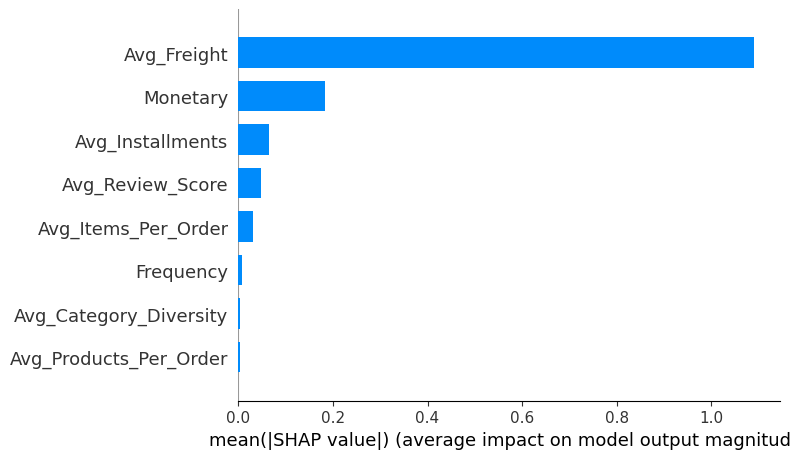

In [ ]:
shap.summary_plot(
shap_values,
X_test_shap,
plot_type="bar"
)

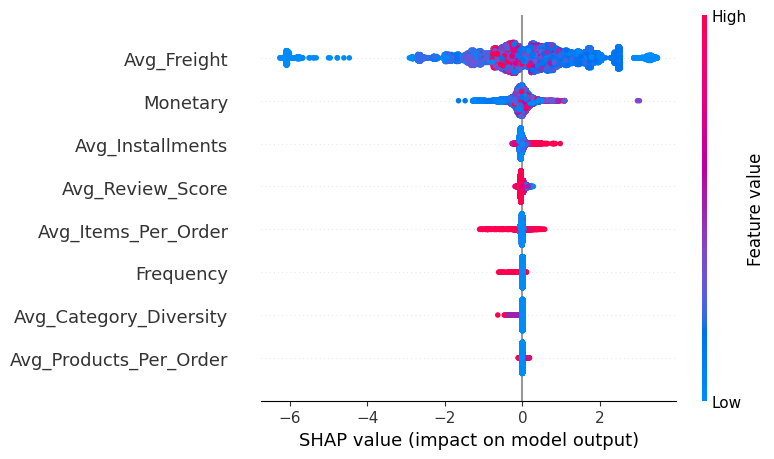

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_shap
)

,purchase_month,Avg_Freight,Orders
0,2016-09,8.49,1
1,2016-10,23.27,265
2,2016-12,8.72,1
3,2017-01,20.91,750
4,2017-02,22.39,1653
5,2017-03,21.65,2546
6,2017-04,21.77,2303
7,2017-05,21.86,3546
8,2017-06,21.73,3135
9,2017-07,21.87,3872


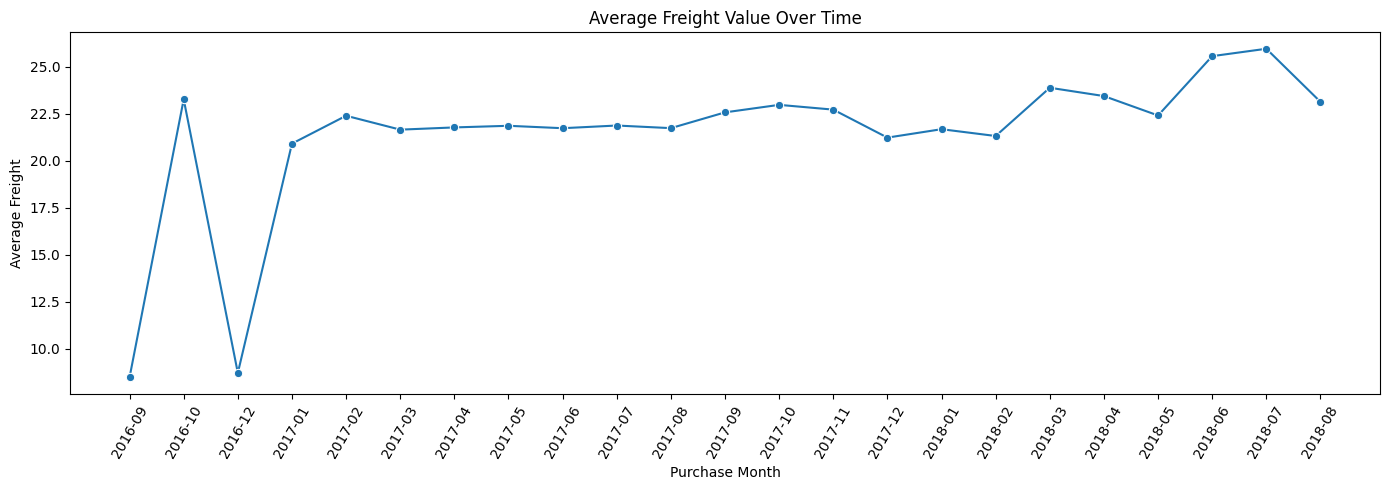

In [ ]:
freight_time_check = master_orders.copy()

freight_time_check["purchase_month"] = (
    freight_time_check["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_freight = (
    freight_time_check
    .groupby("purchase_month")
    .agg(
        Avg_Freight=("total_freight_value", "mean"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

display(monthly_freight)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_freight,
    x="purchase_month",
    y="Avg_Freight",
    marker="o"
)

plt.xticks(rotation=60)
plt.title("Average Freight Value Over Time")
plt.xlabel("Purchase Month")
plt.ylabel("Average Freight")

plt.tight_layout()
plt.show()


In [ ]:
display(
    customer_model
    .groupby("Churn_Risk")
    .agg(
        Customers=("customer_unique_id", "count"),
        Avg_Freight=("Avg_Freight", "mean"),
        Median_Freight=("Avg_Freight", "median"),
        Avg_Monetary=("Monetary", "mean"),
        Avg_Review=("Avg_Review_Score", "mean")
    )
    .round(2)
)

,Customers,Avg_Freight,Median_Freight,Avg_Monetary,Avg_Review
Churn_Risk,,,,,
0,38106,23.99,18.36,169.35,4.20
1,55252,21.94,16.60,162.33,4.12


,purchase_month,Avg_Freight,Orders
0,2016-09,8.49,1
1,2016-10,23.27,265
2,2016-12,8.72,1
3,2017-01,20.91,750
4,2017-02,22.39,1653
5,2017-03,21.65,2546
6,2017-04,21.77,2303
7,2017-05,21.86,3546
8,2017-06,21.73,3135
9,2017-07,21.87,3872


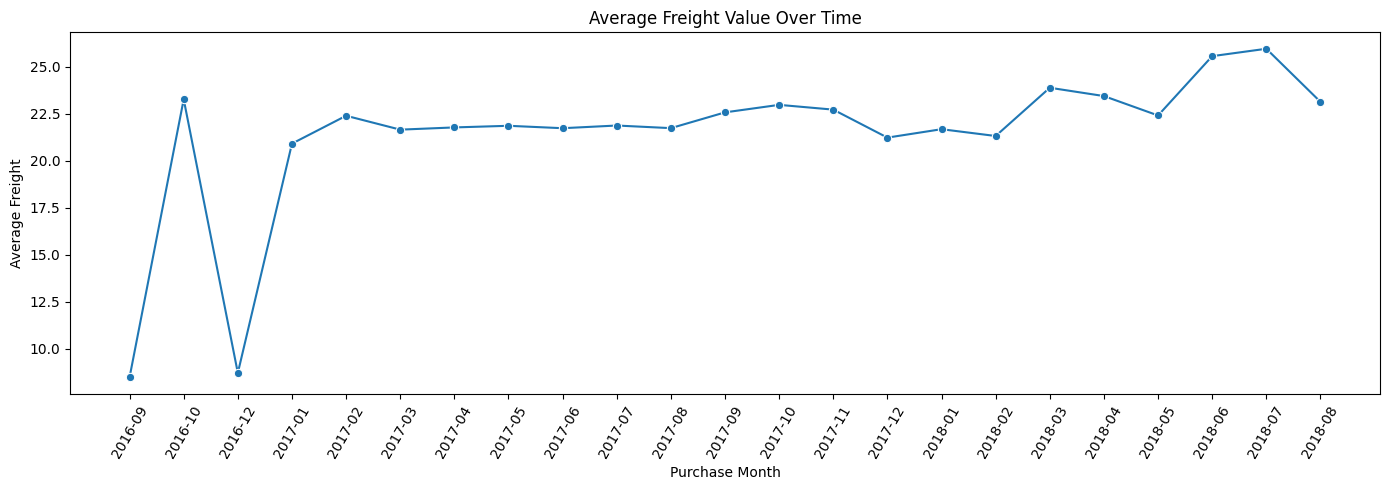

In [ ]:
freight_time_check = master_orders.copy()

freight_time_check["purchase_month"] = (
    freight_time_check["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_freight = (
    freight_time_check
    .groupby("purchase_month")
    .agg(
        Avg_Freight=("total_freight_value", "mean"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

display(monthly_freight)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_freight,
    x="purchase_month",
    y="Avg_Freight",
    marker="o"
)

plt.xticks(rotation=60)
plt.title("Average Freight Value Over Time")
plt.xlabel("Purchase Month")
plt.ylabel("Average Freight")

plt.tight_layout()
plt.show()

In [ ]:
features_no_freight = [
    "Frequency",
    "Monetary",
    "Avg_Items_Per_Order",
    "Avg_Products_Per_Order",
    "Avg_Category_Diversity",
    "Avg_Review_Score",
    "Avg_Installments"
]

X_nf = customer_model[
    features_no_freight
].copy()

X_train_nf, X_test_nf, y_train_nf, y_test_nf = (
    train_test_split(
        X_nf,
        y,
        test_size=0.20,
        stratify=y,
        random_state=RANDOM_STATE
    )
)

imputer_nf = SimpleImputer(strategy="median")

X_train_nf_imp = imputer_nf.fit_transform(
    X_train_nf
)

X_test_nf_imp = imputer_nf.transform(
    X_test_nf
)

xgb_no_freight = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="auc",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_no_freight.fit(
    X_train_nf_imp,
    y_train_nf
)

nf_pred = xgb_no_freight.predict(
    X_test_nf_imp
)

nf_prob = xgb_no_freight.predict_proba(
    X_test_nf_imp
)[:, 1]

no_freight_results = {
    "Accuracy":
        accuracy_score(y_test_nf, nf_pred),

    "Precision":
        precision_score(y_test_nf, nf_pred),

    "Recall":
        recall_score(y_test_nf, nf_pred),

    "F1":
        f1_score(y_test_nf, nf_pred),

    "ROC_AUC":
        roc_auc_score(y_test_nf, nf_prob)
}

comparison = pd.DataFrame(
    [
        log_results,
        xgb_results,
        no_freight_results
    ],
    index=[
        "Logistic Regression",
        "XGBoost",
        "XGBoost without Avg_Freight"
    ]
)

display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.59,0.59,0.99,0.74,0.54
XGBoost,0.78,0.77,0.89,0.82,0.86
XGBoost without Avg_Freight,0.60,0.60,0.95,0.74,0.58
